# DX 704 Week 9 Project

This week's project will build an email spam classifier based on the Enron email data set.
You will perform your own feature extraction, and use naive Bayes to estimate the probability that a particular email is spam or not.
Finally, you will review the tradeoffs from different thresholds for automatically sending emails to the junk folder.

The full project description and a template notebook are available on GitHub: [Project 9 Materials](https://github.com/bu-cds-dx704/dx704-project-09).


## Example Code

You may find it helpful to refer to these GitHub repositories of Jupyter notebooks for example code.

* https://github.com/bu-cds-omds/dx601-examples
* https://github.com/bu-cds-omds/dx602-examples
* https://github.com/bu-cds-omds/dx603-examples
* https://github.com/bu-cds-omds/dx704-examples

Any calculations demonstrated in code examples or videos may be found in these notebooks, and you are allowed to copy this example code in your homework answers.

## Part 1: Download Data Set

We will be using the Enron spam data set as prepared in this GitHub repository.

https://github.com/MWiechmann/enron_spam_data

You may need to download this differently depending on your environment.

In [1]:
!wget https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip

--2026-10-27 19:05:40--  https://github.com/MWiechmann/enron_spam_data/raw/refs/heads/master/enron_spam_data.zip
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/MWiechmann/enron_spam_data/refs/heads/master/enron_spam_data.zip [following]
--2026-10-27 19:05:41--  https://raw.githubusercontent.com/MWiechmann/enron_spam_data/refs/heads/master/enron_spam_data.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8003::154, 2606:50c0:8002::154, 2606:50c0:8000::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8003::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15642124 (15M) [application/zip]
Saving to: ‘enron_spam_data.zip.1’

enron_spam_data.zip 100%[===================>]  14.92M  30.1MB/s    in 0.5s    

2026-10-27 19:05:42 (30.1 

In [2]:
import pandas as pd

In [3]:
# pandas can read the zip file directly
enron_spam_data = pd.read_csv("enron_spam_data.zip")
enron_spam_data

,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14
...,...,...,...,...,...
33711,33711,= ? iso - 8859 - 1 ? q ? good _ news _ c = eda...,"hello , welcome to gigapharm onlinne shop .\np...",spam,2005-07-29
33712,33712,all prescript medicines are on special . to be...,i got it earlier than expected and it was wrap...,spam,2005-07-29
33713,33713,the next generation online pharmacy .,are you ready to rock on ? let the man in you ...,spam,2005-07-30
33714,33714,bloow in 5 - 10 times the time,learn how to last 5 - 10 times longer in\nbed ...,spam,2005-07-30


In [4]:
(enron_spam_data["Spam/Ham"] == "spam").mean()

0.5092834262664611

## Part 2: Design a Feature Extractor

Design a feature extractor for this data set and write out two files of features based on the text.
Don't forget that both the Subject and Message columns are relevant sources of text data.
For each email, you should count the number of repetitions of each feature present.
The auto-grader will assume that you are using a multinomial distribution in the following problems.

In [5]:
enron_spam_data[enron_spam_data.isna().any(axis=1)]

,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
183,183,day 26 - txu lonestar called on 20000 at carthage,NaN,ham,2000-01-25
199,199,is this fri feb 11 a problem for taking vacati...,NaN,ham,2000-01-28
304,304,http : / / www . pge - texas . com / www / gtt...,NaN,ham,2000-02-15
1655,1655,revised,NaN,ham,2000-09-21
...,...,...,...,...,...
32833,32833,NaN,"why paily for pobrne ?\nas a lrpim "" itecd ti ...",spam,2005-05-14
32835,32835,NaN,"are youu stil 3 l pa margin - right : 8 "" alig...",spam,2005-05-14
32898,32898,NaN,pre - ejeculators :\nplease read here for info...,spam,2005-05-19
32926,32926,NaN,there ' s never been a better time to re _ fin...,spam,2005-05-21


In [6]:
enron_spam_data['Spam/Ham'].value_counts()

Spam/Ham
spam    17171
ham     16545
Name: count, dtype: int64

In [7]:
from sklearn.feature_extraction.text import CountVectorizer
import re

spam_copy = enron_spam_data.copy()
spam_copy['full_email'] = spam_copy['Subject'].fillna('').astype(str) + ' ' + spam_copy['Message'].fillna('').astype(str)
spam_copy['full_email'] = spam_copy['full_email'].str.lower()

def replace_num_with_token(text):
    """
        Replace digits (including decimals) with <NUM>
    """
    text_lower = str(text).lower()
    text_clean = re.sub(r'\b\d+(?:\.\d+)?\b|\d+', '<NUM>', text_lower)
    return text_clean

spam_copy['full_email_clean'] = spam_copy['full_email'].apply(replace_num_with_token)

corpus = spam_copy['full_email_clean'].copy()

vectorizer = CountVectorizer(
    ngram_range=(1, 2),          # using unigram and bigrams for better context
    stop_words='english',        # removing words like 'and', 'the', etc. that provide little value in predicting spam
    min_df=3,                    # ngram must appear within at least 3 emails
    max_features=3000            # top 3K most frequent features
)

X = vectorizer.fit_transform(corpus)

Assign a row to the test data set if `Message ID % 30 == 0` and assign it to the training data set otherwise.
Write two files, "train-features.tsv" and "test-features.tsv" with two columns, Message ID and features_json.
The features_json column should contain a JSON dictionary where the keys are your feature names and the values are integer feature values.
This will give us a sparse feature representation.


In [8]:
import json
features = vectorizer.get_feature_names_out()
X_sparse = vectorizer.transform(corpus)

# JSON dictionary
features_json_list = []
for row in X_sparse:
    indices = row.indices
    counts = row.data

    row_dict = {features[i]: int(c) for i, c in zip(indices, counts)}
    features_json_list.append(json.dumps(row_dict))

df = pd.DataFrame({
    'Message ID': spam_copy['Message ID'],
    'Spam/Ham': spam_copy['Spam/Ham'],
    'features_json': features_json_list
})

# Splitting test data based on Message ID % 30 == 0
test_samples = df['Message ID'] % 30 == 0
test = df[test_samples]
train = df[~test_samples]

# Spam/Ham target
y_test = test['Spam/Ham']
y_train = test['Spam/Ham']

# Final dataset splits for TSV files (excludes target)
test_df = test[['Message ID', 'features_json']]
train_df = train[['Message ID', 'features_json']]

In [9]:
test_df.to_csv('test-features.tsv', sep='\t', index=False)
test_df.head()

,Message ID,features_json
0,0,{}
30,30,"{""attached"": 2, ""attached file"": 2, ""calls"": 1..."
60,60,"{""jackie"": 1, ""lloyd"": 1, ""new"": 2, ""num"": 1, ..."
90,90,"{""actuals"": 1, ""enron"": 3, ""hpl"": 2, ""january""..."
120,120,"{""according"": 1, ""actuals"": 1, ""black"": 4, ""cc..."


In [10]:
train_df.to_csv('train-features.tsv', sep='\t', index=False)
train_df.head()

,Message ID,features_json
1,1,"{""advises"": 1, ""america"": 1, ""america corp"": 1..."
2,2,"{""calpine"": 2, ""daily"": 2, ""doc"": 1, ""gas"": 2,..."
3,3,"{""accounting"": 1, ""arrangement"": 1, ""care"": 1,..."
4,4,"{""allen"": 3, ""allocated"": 2, ""allocation"": 3, ..."
5,5,"{""active"": 1, ""advice"": 1, ""buying"": 1, ""day"":..."


Submit "train-features.tsv" and "test-features.tsv" in Gradescope.

Hint: these features will be graded based on the test accuracy of a logistic regression based on the training features.
This is to make sure that your feature set is not degenerate; you do not need to compute this regression yourself.
You can separately assess your feature quality based on your results in part 6.

## Part 3: Compute Conditional Probabilities

Based on your training data, compute appropriate conditional probabilities for use with naïve Bayes.
Use of additive smoothing with $\alpha=1$ to avoid zeros.


In [11]:
import numpy as np

feature_idx_dict = {feat: i for i, feat in enumerate(features)}
feature_size = len(features)

spam_counts = np.zeros(feature_size, dtype=np.int64)
ham_counts = np.zeros(feature_size, dtype=np.int64)

# get feature counts for spam and ham samples
for i, row in train.iterrows():
    is_spam = (row['Spam/Ham'] == 'spam')
    row_dict = json.loads(row['features_json'])

    for feat, count in row_dict.items():
        if feat in feature_idx_dict:
            idx = feature_idx_dict[feat]
            if is_spam:
                spam_counts[idx] += count
            else:
                ham_counts[idx] += count

# get totals per Spam/Ham
total_ngrams_spam = spam_counts.sum()
total_ngrams_ham = ham_counts.sum()

# compute conditional probabilities with additive smoothing
alpha = 1
p_given_spam = (spam_counts + alpha) / (total_ngrams_spam + feature_size)
p_given_ham = (ham_counts + alpha) / (total_ngrams_ham + feature_size)

prob_df = pd.DataFrame({
    'feature': features,
    'ham_probability': p_given_ham,
    'spam_probability': p_given_spam
})

prob_df.head(15)

,feature,ham_probability,spam_probability
0,aa,0.000088,0.000118
1,ability,0.000243,0.000362
2,able,0.000597,0.000494
3,absolutely,0.000038,0.000256
4,accept,0.000135,0.000214
5,acceptance,0.000071,0.000340
6,accepted,0.000090,0.000085
7,access,0.000690,0.000621
8,according,0.000406,0.000273
9,account,0.000284,0.002342


Save the conditional probabilities in a file "feature-probabilities.tsv" with columns feature, ham_probability and spam_probability.

In [12]:
prob_df.to_csv('feature-probabilities.tsv', sep='\t', index=False)

Submit "feature-probabilities.tsv" in Gradescope.

## Part 4: Implement a Naïve Bayes Classifier

Implement a naïve Bayes classifier based on your previous feature probabilities.

In [13]:
total_emails = len(train)
num_spam = (train['Spam/Ham'] == 'spam').sum()
num_ham = (train['Spam/Ham'] == 'ham').sum()

p_spam = num_spam / total_emails
p_ham = num_ham / total_emails

# convert to log prob
log_p_spam = np.log(p_spam)
log_p_ham = np.log(p_ham)

# convert to dict instead of df - ngram probabilities for Spam/Ham
prob_dict = prob_df.set_index('feature').to_dict()
log_spam_prob = {feat: np.log(prob) for feat, prob in prob_dict['spam_probability'].items()}
log_ham_prob = {feat: np.log(prob) for feat, prob in prob_dict['ham_probability'].items()}

# prediction probabilities for training data
predictions = []

for i, row in train.iterrows():
    message_id = row['Message ID']
    row_dict = json.loads(row['features_json'])

    # initialize with log priors
    log_prob_spam = log_p_spam
    log_prob_ham = log_p_ham

    # accumulate log probs weighted by feature counts
    for feat, count in row_dict.items():
        if feat in log_spam_prob:
            log_prob_spam += count * log_spam_prob[feat]
            log_prob_ham += count * log_ham_prob[feat]

    predictions.append({
        'Message ID': message_id,
        'log_ham': log_prob_ham,
        'log_spam': log_prob_spam
    })

pred_df = pd.DataFrame(predictions)

# normalize log probs (log-sum-exp)
def normalize_log_probs(row):
    m = max(row['log_ham'], row['log_spam'])
    ham_exp = np.exp(row['log_ham'] - m)
    spam_exp = np.exp(row['log_spam'] - m)
    total = ham_exp + spam_exp

    return pd.Series({
        'ham': ham_exp / total,
        'spam': spam_exp / total
    })

norm_probs = pred_df.apply(normalize_log_probs, axis=1)
pred_df['ham'] = norm_probs['ham']
pred_df['spam'] = norm_probs['spam']

final_pred_probs = pred_df[['Message ID', 'ham', 'spam']]
final_pred_probs.sample(5)
    

,Message ID,ham,spam
15693,16235,2.983640e-08,1.000000e+00
30060,31097,2.038169e-185,1.000000e+00
31665,32757,7.887225e-26,1.000000e+00
28830,29825,2.132407e-01,7.867593e-01
22818,23605,1.000000e+00,5.999330e-22


Save your prediction probabilities to "train-predictions.tsv" with columns Message ID, ham and spam.

In [14]:
final_pred_probs.to_csv('train-predictions.tsv', sep='\t', index=False)

Submit "train-predictions.tsv" in Gradescope.

## Part 5: Predict Spam Probability for Test Data

Use your previous classifier to predict spam probability for the test data.
If the test data has tokens that you did not model, just ignore them.

In [15]:
# maintains training prior probs
total_emails = len(train)
num_spam = (train['Spam/Ham'] == 'spam').sum()
num_ham = (train['Spam/Ham'] == 'ham').sum()

p_spam = num_spam / total_emails
p_ham = num_ham / total_emails

# convert to log prob
log_p_spam = np.log(p_spam)
log_p_ham = np.log(p_ham)

# convert to dict instead of df - ngram probabilities for Spam/Ham
prob_dict = prob_df.set_index('feature').to_dict()
log_spam_prob = {feat: np.log(prob) for feat, prob in prob_dict['spam_probability'].items()}
log_ham_prob = {feat: np.log(prob) for feat, prob in prob_dict['ham_probability'].items()}

# prediction probabilities for testing data
predictions = []

for i, row in test.iterrows():
    message_id = row['Message ID']
    row_dict = json.loads(row['features_json'])

    # initialize with log priors
    log_prob_spam = log_p_spam
    log_prob_ham = log_p_ham

    # accumulate log probs weighted by feature counts
    for feat, count in row_dict.items():
        if feat in log_spam_prob:
            log_prob_spam += count * log_spam_prob[feat]
            log_prob_ham += count * log_ham_prob[feat]

    predictions.append({
        'Message ID': message_id,
        'log_ham': log_prob_ham,
        'log_spam': log_prob_spam
    })

pred_df = pd.DataFrame(predictions)

norm_probs = pred_df.apply(normalize_log_probs, axis=1)
pred_df['ham'] = norm_probs['ham']
pred_df['spam'] = norm_probs['spam']

final_pred_probs = pred_df[['Message ID', 'ham', 'spam']]
final_pred_probs.sample(5)
    

,Message ID,ham,spam
819,24570,1.876190e-25,1.0
874,26220,3.307856e-66,1.0
853,25590,2.284646e-13,1.0
1079,32370,1.363303e-117,1.0
771,23130,1.000000e+00,0.0


Save your prediction probabilities in "test-predictions.tsv" with the same columns as "train-predictions.tsv".

In [16]:
final_pred_probs.to_csv('test-predictions.tsv', sep='\t', index=False)

Submit "test-predictions.tsv" in Gradescope.

## Part 6: Construct ROC Curve

For every probability threshold from 0.01 to .99 in increments of 0.01, compute the false and true positive rates from the test data using the spam class for positives.
That is, if the predicted spam probability is greater than or equal to the threshold, predict spam.

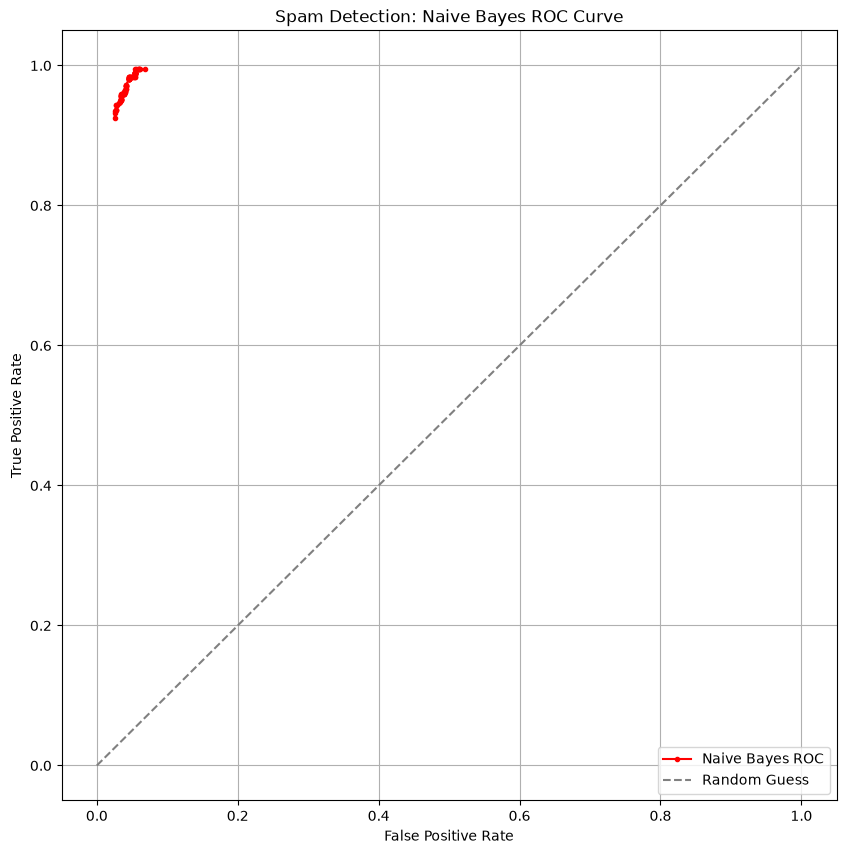

In [17]:
import matplotlib.pyplot as plt

test_pred = pd.read_csv('test-predictions.tsv', sep='\t')

# merge with true targets
eval_df = pd.merge(test_pred, test[['Message ID', 'Spam/Ham']], on='Message ID')

actual_positive = (eval_df['Spam/Ham'] == 'spam')
actual_negative = (eval_df['Spam/Ham'] == 'ham')

total_positive = actual_positive.sum()
total_negative = actual_negative.sum()

# compute false and true positive trates from 0.01 to 0.99
thresholds = np.arange(0.01, 1.00, 0.01)
roc_data = []

for t in thresholds:
    predicted_positive = eval_df['spam'] >= t

    # confusion matrix
    true_positives = (predicted_positive & actual_positive).sum()
    false_positives = (predicted_positive & actual_negative).sum()

    tpr = true_positives / total_positive
    fpr = false_positives / total_negative

    roc_data.append({
        'threshold': t,
        'false_positive_rate': fpr,
        'true_positive_rate': tpr
    })

roc_df = pd.DataFrame(roc_data)

plt.figure(figsize=(10,10))
plt.plot(roc_df['false_positive_rate'], roc_df['true_positive_rate'], marker='.', color='red', label='Naive Bayes ROC')
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Spam Detection: Naive Bayes ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

Save this data in a file "roc.tsv" with columns threshold, false_positive_rate and true_positive rate.

In [19]:
roc_df.to_csv('roc.tsv', sep='\t', index=False)

Submit "roc.tsv" in Gradescope.

## Part 7: OpenAI API Key

Sign up for an OpenAI API acount at https://platform.openai.com/.
If you already have an OpenAI account (e.g. for ChatGPT), you may reuse that account.

Create a "dx704" project at https://platform.openai.com/settings/organization/projects, setup a $10/month spend limit, and create an API key for the project at https://platform.openai.com/api-keys.
You will use this API key for projects in later weeks.


No submission needed.

## Part 8: Code

Please submit a Jupyter notebook that can reproduce all your calculations and recreate the previously submitted files.
You do not need to provide code for data collection if you did that by manually.

## Part 9: Acknowledgements

If you discussed this assignment with anyone, please acknowledge them here.
If you did this assignment completely on your own, simply write none below.

If you used any libraries not mentioned in this module's content, please list them with a brief explanation what you used them for. If you did not use any other libraries, simply write none below.

If you used any generative AI tools, please add links to your transcripts below, and any other information that you feel is necessary to comply with the generative AI policy. If you did not use any generative AI tools, simply write none below.